# SOUND / SIGNAL
### Reproducible analysis notebook

**Central question.** Can we identify measurable patterns in music that explain popularity, emotional perception, genre identity and the evolution of mainstream music?

This notebook reads the cleaned data and saved results produced by the scripts in `scripts/`, shows each investigation, and re-derives a set of headline numbers directly from the cleaned tables. All findings are descriptive associations. None of them establishes what causes a song to succeed.

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np, pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "sound_signal").exists())
sys.path.insert(0, str(ROOT / "src"))
from sound_signal import figures, findings, stats
from sound_signal.config import AUDIO_FEATURES, PROCESSED_DIR, RAW_DIR

# Set to True to rebuild everything from the raw files first (about 30 minutes).
RUN_PIPELINE = False
if RUN_PIPELINE:
    for script in ("01_download.py", "02_clean_merge.py", "03_musicbrainz.py", "04_analyze.py"):
        subprocess.run([sys.executable, str(ROOT / "scripts" / script)], check=True)

R = findings.load_results()
written = findings.build(R)
findings.check(written)
pd.set_option("display.max_columns", 30, "display.width", 160, "display.float_format", "{:,.3f}".format)

def show_figure(name):
    figure = figures.ALL[name](R)
    try:
        display(figure)
    finally:
        figures.plt.close(figure)

29 written claims match the results


## 1. Data and quality
Row counts, exclusions and join rates are logged by the cleaning step.

In [2]:
q = R["data_quality"]
rows = []
for name, key in [("Spotify tracks with genres", "spotify_tracks_genre"), ("Spotify 1.2M catalogue", "spotify_catalogue"), ("Spotify 1M tracks", "spotify_1m"), ("Top 50 by country, 2023-2025", "charts_2023_2025"), ("Last.fm tags", "lastfm_tags")]:
    s = q[key]
    rows.append({"source": name, "raw rows": s["rows_raw"], "invalid audio rows": s["invalid_audio_rows"], "clean rows": s.get("rows_clean", s.get("join", {}).get("matched_tracks"))})
display(pd.DataFrame(rows))
print("Billboard join:", q["billboard"]["join"])
print("2017-2021 chart audio match:", q["merge"]["charts_2017_2021_to_audio"])
pd.DataFrame(q["merge"]["feature_agreement_pearson"]).T

Billboard join: {'key': 'song_id supplied by the source', 'songs': 29389, 'songs_matched': 24210, 'song_match_pct': 82.38, 'chart_slot_match_pct': 86.62}
2017-2021 chart audio match: {'songs_by_tier': {'unmatched': 74654, 'spotify_id': 19080, 'artist_title_validated': 8903}, 'stream_share_pct_by_tier': {'artist_title_validated': 16.08, 'spotify_id': 66.78, 'unmatched': 17.14}}


,source,raw rows,invalid audio rows,clean rows
0,Spotify tracks with genres,114000,323,113229
1,Spotify 1.2M catalogue,1204025,16259,1187646
2,Spotify 1M tracks,1159764,7489,1152275
3,"Top 50 by country, 2023-2025",2110316,161,2106630
4,Last.fm tags,683010,0,594903


,shared_ids,energy,valence,tempo,loudness
charts_2023_2025 / spotify_tracks_genre,508.000,0.999,1.000,0.981,0.998
charts_2023_2025 / spotify_1m,942.000,1.000,1.000,0.995,0.998
charts_2023_2025 / billboard_audio,305.000,0.997,0.999,0.905,0.988
charts_2023_2025 / spotify_catalogue,263.000,0.999,1.000,1.000,0.998
spotify_tracks_genre / spotify_1m,"36,208.000",1.000,1.000,1.000,1.000
spotify_tracks_genre / billboard_audio,"1,658.000",0.998,0.996,0.948,0.995
spotify_tracks_genre / spotify_catalogue,"4,723.000",1.000,1.000,0.993,1.000
spotify_1m / billboard_audio,"6,559.000",0.997,0.995,0.939,0.991
spotify_1m / spotify_catalogue,"79,380.000",1.000,1.000,0.995,1.000
billboard_audio / spotify_catalogue,"4,082.000",0.995,0.997,0.989,0.985


### Reproducibility check
These figures are recalculated here from the cleaned tables and compared with the saved results.

In [3]:
if (PROCESSED_DIR / "genre_tracks.parquet").exists():
    g = pd.read_parquet(PROCESSED_DIR / "genre_tracks.parquet", columns=["track_id", "genre", "speechiness", "energy", "acousticness"])
    g = g[~g.genre.isin(["comedy", "sleep"]) & (g.speechiness <= .66)].drop_duplicates("track_id")
    live = g[["energy", "acousticness"]].rank().corr().iloc[0, 1]
    saved = next(p for p in R["emotion"]["pairs"] if {p["a"], p["b"]} == {"energy", "acousticness"})["spearman"]
    print(f"Energy-acousticness Spearman: recomputed {live:.4f}, saved {saved:.4f}")
    assert abs(live - saved) < 1e-3
    w = pd.read_parquet(PROCESSED_DIR / "billboard_weeks.parquet")
    print(f"Billboard weekly rows: {len(w):,}, weeks {w.week.min().date()} to {w.week.max().date()}")
else:
    print("Cleaned data not found. Run the pipeline to enable this check; saved results are still shown.")

Energy-acousticness Spearman: recomputed -0.7275, saved -0.7275
Billboard weekly rows: 327,866, weeks 1958-08-02 to 2021-05-29


## 2. Descriptive statistics

In [4]:
pd.DataFrame(R["overview"]["descriptive_catalogue"]).T.assign(outlier_pct_kept=pd.Series(R["overview"]["outlier_pct_tukey_kept"]))

,n,mean,median,sd,q1,q3,min,max,skewness,excess_kurtosis,outlier_pct_kept
danceability,"1,187,646.000",0.496,0.502,0.188,0.359,0.634,0.000,1.000,-0.081,-0.638,0.000
energy,"1,187,646.000",0.512,0.527,0.294,0.257,0.768,0.000,1.000,-0.096,-1.216,0.000
loudness,"1,187,646.000",-11.715,-9.723,6.892,-15.070,-6.692,-58.925,7.234,-1.250,1.473,3.396
speechiness,"1,187,646.000",0.083,0.044,0.113,0.035,0.072,0.022,0.969,4.247,22.718,13.884
acousticness,"1,187,646.000",0.444,0.382,0.385,0.037,0.858,0.000,0.996,0.175,-1.630,0.000
instrumentalness,"1,187,646.000",0.281,0.008,0.376,0.000,0.713,0.000,1.000,0.807,-1.158,0.000
liveness,"1,187,646.000",0.201,0.125,0.180,0.097,0.244,0.007,1.000,2.282,5.340,7.920
valence,"1,187,646.000",0.431,0.407,0.269,0.195,0.646,0.000,1.000,0.251,-1.049,0.000
tempo,"1,187,646.000",118.030,116.990,30.417,94.455,137.250,30.018,248.930,0.397,-0.300,0.446
duration_min,"1,187,646.000",4.041,3.739,1.900,2.916,4.745,0.500,15.000,1.614,4.669,5.310


Outliers are flagged with Tukey's rule and kept, because extreme values such as a spoken intro or a very long track are real recordings. Rank-based tests limit their influence.

## 3. Investigation A: the emotional structure of music

#### Where does recorded music sit on a map of mood?

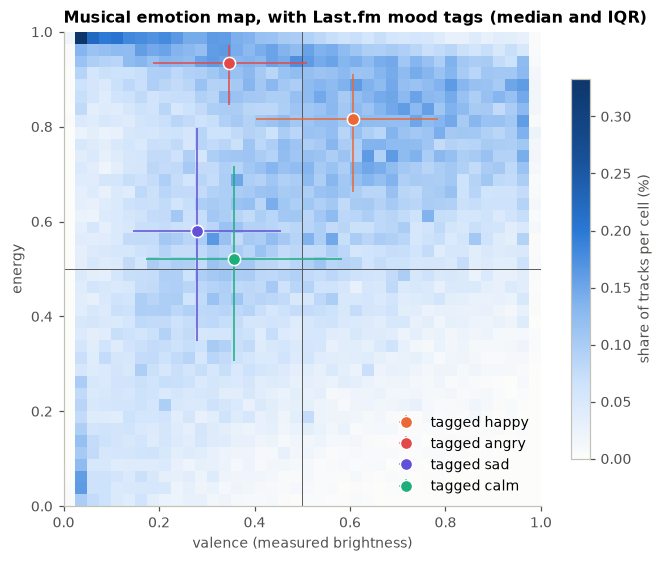

In [5]:
show_figure("01_emotion_map")

**Interpretation.** Most tracks are energetic: 71% score at least 0.5 on energy, and only 8% combine high valence with low energy. The serene corner is thin in this sample, which suggests calm music is rarely measured as bright.

#### Which audio measurements carry the same information?

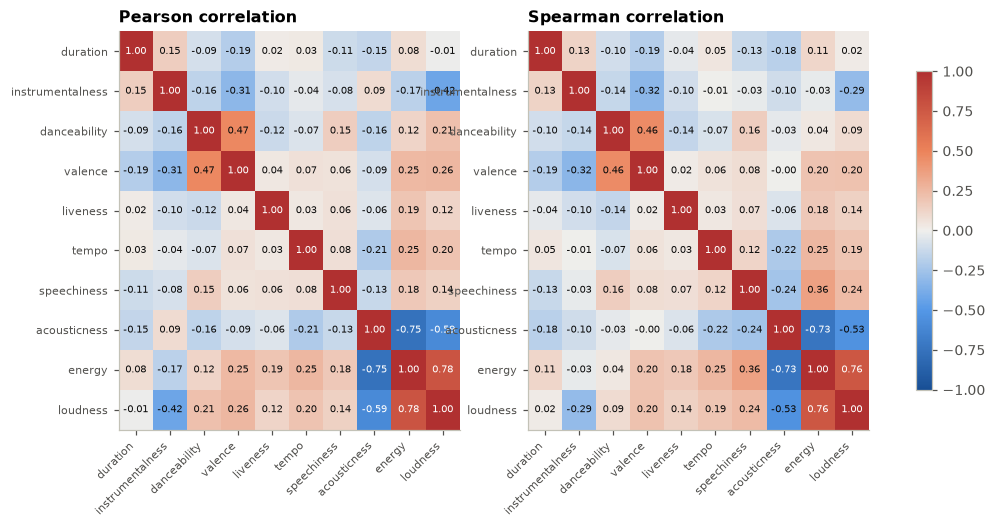

In [6]:
show_figure("02_correlation_heatmap")

**Interpretation.** Energy and acousticness are close to opposites (Spearman -0.73), and energy clusters tightly with loudness. Valence moves with danceability (0.46), so bright-sounding tracks also tend to be easier to dance to. Tempo has almost no link with valence (0.06) and only a modest one with energy (0.25).

#### Do listeners' mood tags agree with the measured audio?

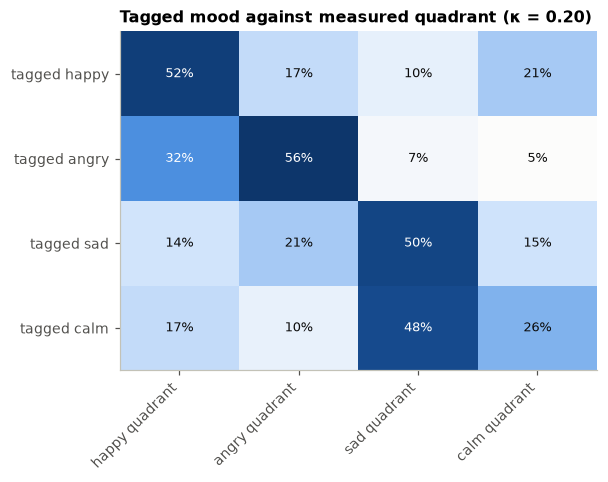

In [7]:
show_figure("03_mood_agreement")

**Interpretation.** Partly. Tags separate energy well (ε² 0.24) and valence less well (ε² 0.14). Agreement on the four-way mood quadrant is weak: Cohen's κ is 0.20 (95% CI 0.19 to 0.20). Calm-tagged music has a median valence of only 0.36, close to sad-tagged music at 0.28, so valence does not capture the difference people hear between calm and sad.

In [8]:
pd.DataFrame(R["emotion"]["pairs"]).drop(columns=["pearson_ci", "spearman_ci"])

,a,b,pearson,spearman,n,p,q_fdr
0,energy,valence,0.249,0.202,87492,0.000,0.000
1,energy,danceability,0.119,0.038,87492,0.000,0.000
2,energy,tempo,0.251,0.251,87492,0.000,0.000
3,energy,acousticness,-0.751,-0.728,87492,0.000,0.000
4,valence,danceability,0.473,0.461,87492,0.000,0.000
5,valence,tempo,0.067,0.058,87492,0.000,0.000
6,valence,acousticness,-0.089,-0.004,87492,0.000,0.000
7,danceability,tempo,-0.066,-0.071,87492,0.000,0.000
8,danceability,acousticness,-0.161,-0.035,87492,0.000,0.000
9,tempo,acousticness,-0.208,-0.216,87492,0.000,0.000


## 4. Investigation B: the popularity paradox

#### How is popularity distributed across tracks?

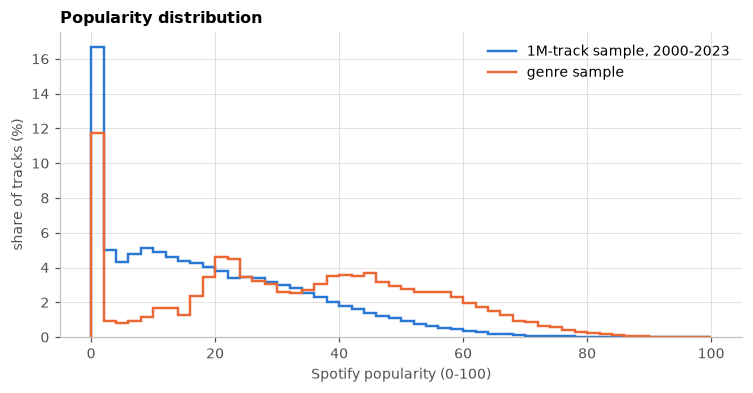

In [9]:
show_figure("04_popularity_distribution")

**Interpretation.** Popularity is strongly right-skewed. The median track scores 16 out of 100, and 13% score exactly zero. Scores are stable measurements: for 34,872 tracks seen in two separately collected datasets, the rank correlation is 0.98.

#### How do popular tracks differ from unpopular ones?

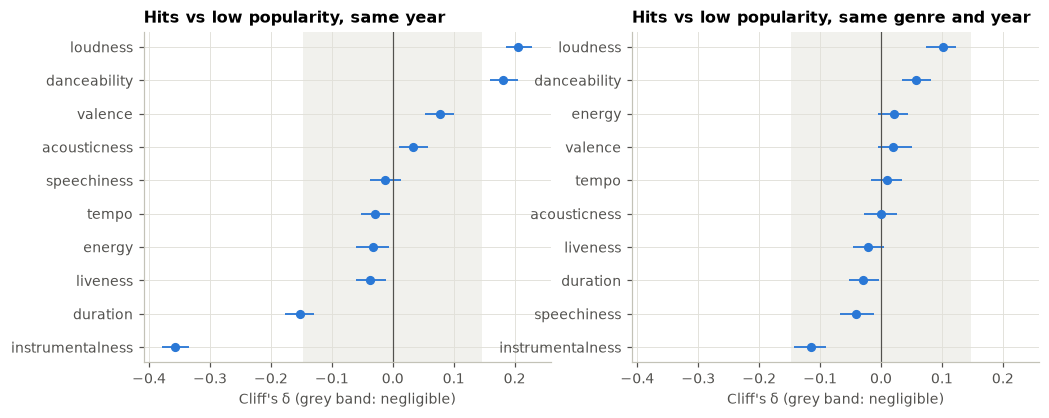

In [10]:
show_figure("05_hit_profile")

**Interpretation.** The largest gap is in instrumentalness (Cliff's δ -0.36): the typical hit scores close to zero on it. Hits are also louder (δ 0.21), more danceable (0.18) and shorter (-0.15). Inside the same genre and year every one of these gaps shrinks to a negligible size, the largest being -0.11 for instrumentalness and 0.10 for loudness.

#### How much of popularity can each kind of information predict?

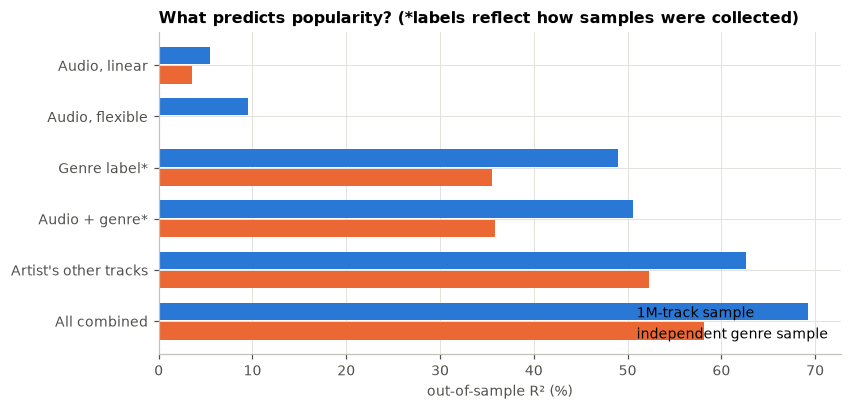

In [11]:
show_figure("06_prediction_ladder")

**Interpretation.** Audio alone predicts 9.5% of the variation in unseen tracks at best. Knowing the artist's other tracks predicts 62.7%. An independently collected sample gives the same order: 3.6% for audio and 52.3% for artist. Genre scores high here (49.0%), but those labels reflect how the samples were gathered, so that bar should not be read as the effect of genre.

**Is popularity confined to a narrow range?** Only loosely. 48% of hits fall inside the central band of hit values on all nine features, and so do 35% of other tracks. Hits look 10% less spread out overall, but within genre the ratio is 1.00, which means no narrower. The apparent formula mostly reflects which styles hits come from.

In [12]:
pd.DataFrame(R["popularity"]["regression"]["coefficients"]).assign(unit="percentile points per SD")

,term,beta,se,ci,p,q_fdr,unit
0,danceability,1.115,0.089,"[0.94126, 1.2885]",0.000,0.000,percentile points per SD
1,energy,-0.934,0.137,"[-1.2023, -0.665]",0.000,0.000,percentile points per SD
2,loudness,2.897,0.157,"[2.5906, 3.2043]",0.000,0.000,percentile points per SD
3,speechiness,-0.394,0.067,"[-0.52436, -0.26325]",0.000,0.000,percentile points per SD
4,acousticness,0.259,0.103,"[0.056428, 0.46168]",0.012,0.014,percentile points per SD
5,instrumentalness,-1.705,0.105,"[-1.9105, -1.5002]",0.000,0.000,percentile points per SD
6,liveness,-0.028,0.060,"[-0.14588, 0.090705]",0.648,0.648,percentile points per SD
7,valence,-1.534,0.078,"[-1.6872, -1.3813]",0.000,0.000,percentile points per SD
8,tempo,0.199,0.037,"[0.12672, 0.27084]",0.000,0.000,percentile points per SD
9,duration_min,-1.712,0.076,"[-1.8604, -1.5644]",0.000,0.000,percentile points per SD


## 5. Investigation C: evolution of mainstream music

#### How has mainstream music changed since 1959, and did the wider catalogue change with it?

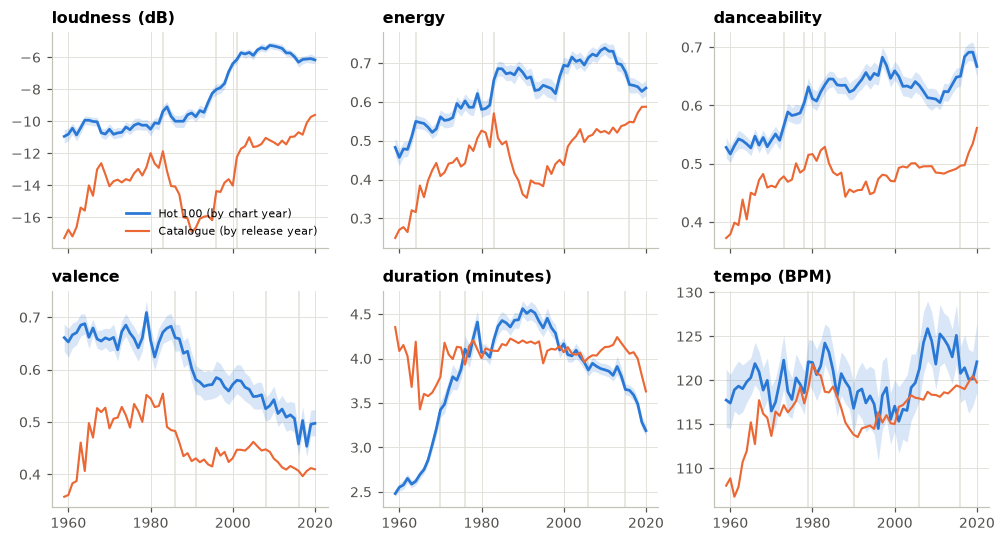

In [13]:
show_figure("07_evolution_timeline")

**Interpretation.** Hot 100 music became louder by 1.01 dB per decade, less acoustic by 0.061 and less bright by 0.033 valence points per decade. The median song debuting in the 2010s has valence 0.47, against 0.70 in the 1960s. The wider catalogue is thinly sampled before the 1970s and its valence rose until about 1980, so its overall slope is about half as steep (0.017 per decade). Tempo shows no reliable long-run trend on the chart.

#### How do feature distributions differ between decades?

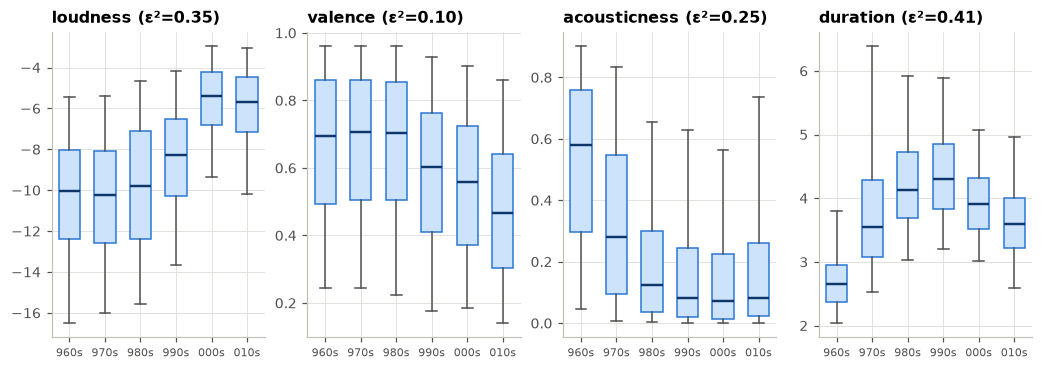

In [14]:
show_figure("08_decade_distributions")

**Interpretation.** Decade explains the most variation in duration (ε² 0.41) and loudness (0.35), and almost none in tempo (0.006). The median charting song grew from 2.65 minutes in the 1960s to 4.30 in the 1990s, then shortened to 3.59 in the 2010s.

In [15]:
pd.DataFrame({f: {"Hot 100 per decade": t["chart"]["per_decade"], "Hot 100 q": t["chart"]["q_fdr"], "catalogue per decade": t["catalogue"]["per_decade"],
                  "catalogue q": t["catalogue"]["q_fdr"], "change points": ", ".join(str(c["year"]) for c in t["chart"]["change_points"]),
                  "anomalous years": ", ".join(str(a["year"]) for a in t["chart"]["anomalies"])} for f, t in R["evolution"]["trends"].items()}).T

,Hot 100 per decade,Hot 100 q,catalogue per decade,catalogue q,change points,anomalous years
tempo,0.397,0.062,1.183,0.000,"1979, 1990, 2006, 2016",
loudness,1.010,0.000,0.734,0.000,"1983, 1996, 2001",1984
energy,0.037,0.000,0.035,0.000,"1964, 1983, 2000, 2016",
danceability,0.022,0.000,0.011,0.000,"1973, 1978, 1983, 2016",
valence,-0.033,0.000,-0.017,0.000,"1986, 1991, 2008, 2016",1979
duration_min,0.101,0.139,0.002,0.757,"1970, 1976, 2006, 2015","1979, 1982, 2020"
acousticness,-0.061,0.000,-0.055,0.000,"1965, 1970, 1976, 1983",
speechiness,0.011,0.000,0.004,0.000,"1993, 2001, 2008, 2016","2000, 2016, 2020"


## 6. Investigation D: genre identity and overlap

#### How differently are genres distributed on key features?

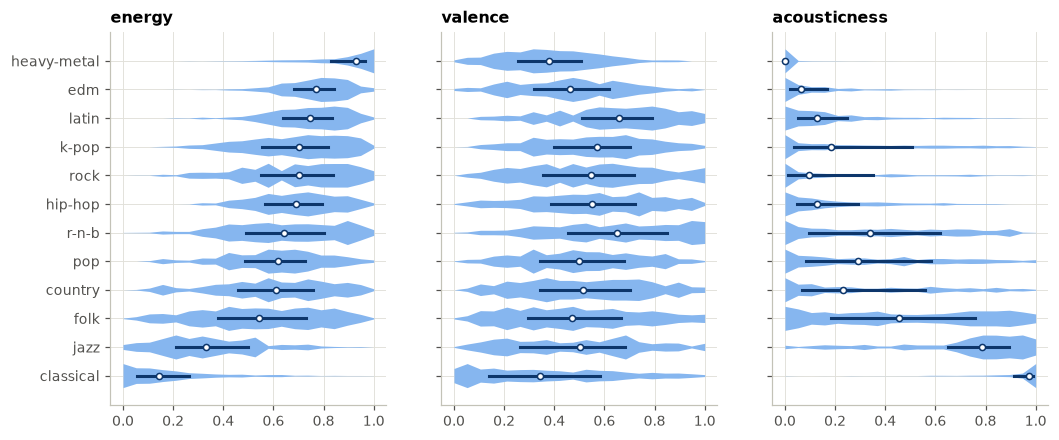

In [16]:
show_figure("09_genre_violins")

**Interpretation.** Genres differ most on acousticness (ε² 0.51) and energy (0.44). Tempo (0.07) and liveness (0.06) say little about genre. Spreads still overlap widely, so a single feature rarely identifies a genre.

#### Which genres sound alike?

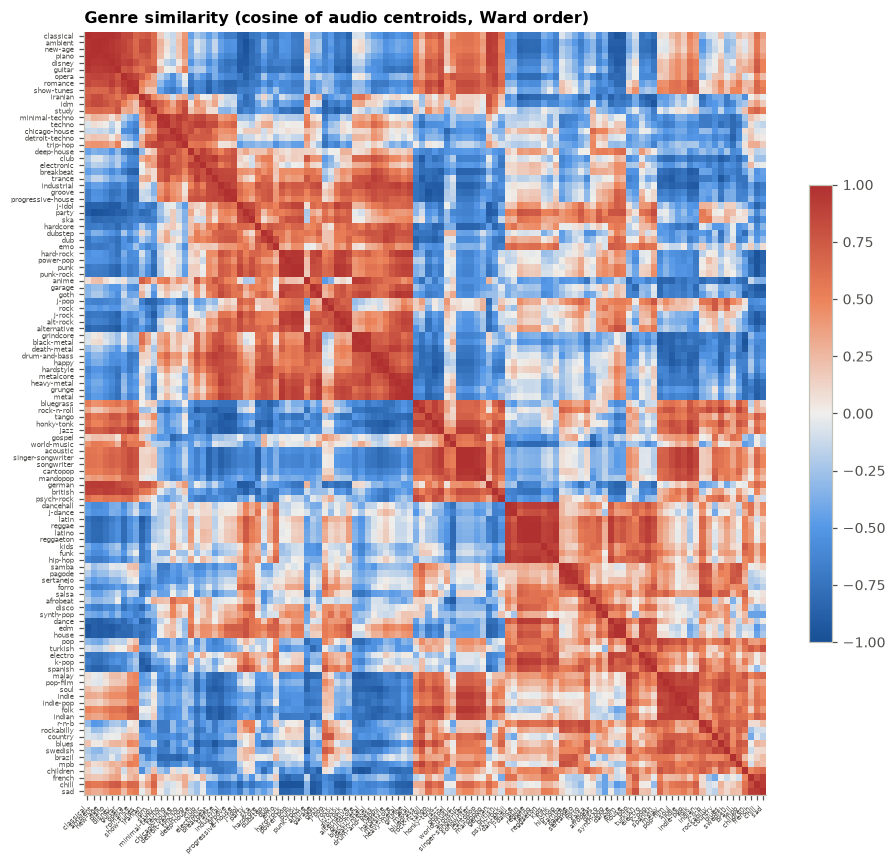

In [17]:
show_figure("10_genre_similarity")

**Interpretation.** Blocks along the diagonal are families of genres with similar audio profiles. From audio alone, a simple classifier names the right genre 12.1% of the time, about 13 times chance among 112 genres, and puts it in the top five 35% of the time. It tested on artists it had not seen. Sonically specific styles such as grindcore and minimal techno are among the easiest to recover. Labels based on language or place, such as German and Swedish, are among the hardest.

**Overlap.** 19% of tracks carry more than one genre label. Genres that share tracks also sound closer (rank correlation -0.34 between overlap and audio distance). Treat the very top pairs with care: 'singer-songwriter' and 'songwriter' are the same list, and pairs whose names contain each other, such as dub and dubstep, may partly reflect keyword searches.

#### What musical types appear if genre labels are ignored?

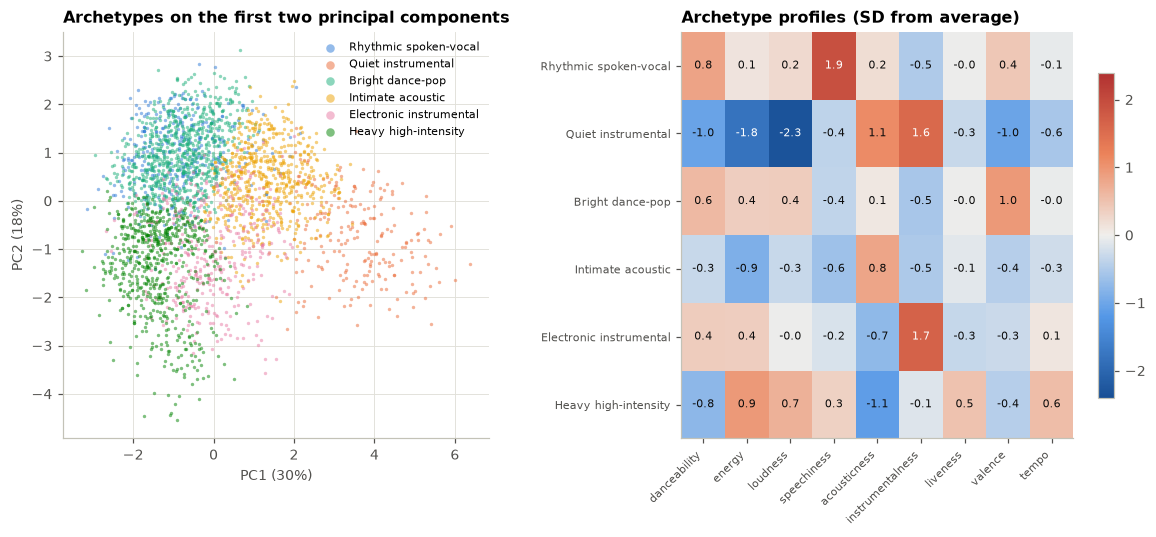

In [18]:
show_figure("11_archetypes_pca")

**Interpretation.** Clustering the audio alone gives 6 recurring archetypes, chosen for separation and stability. They line up strongly with genre labels the algorithm never saw (Cramér's V 0.52). The boundaries are soft: the silhouette score is only 0.17, so these are regions of a continuum, and archetype says little about popularity (ε² 0.016).

In [19]:
pd.DataFrame(R["genre"]["tests"]).drop(columns="assumptions")

,feature,n,groups,anova_f,anova_p,welch_f,welch_df2,welch_p,eta_squared,kruskal_h,kruskal_p,epsilon_squared,kruskal_q_fdr
0,acousticness,111271,112,925.880,0.000,"1,842.500","37,701.000",0.000,0.480,"56,512.000",0.000,0.507,0.000
1,energy,111271,112,845.780,0.000,"1,100.400","37,711.000",0.000,0.458,"49,088.000",0.000,0.441,0.000
2,danceability,111271,112,634.440,0.000,831.480,"37,712.000",0.000,0.388,"41,697.000",0.000,0.374,0.000
3,instrumentalness,111271,112,782.930,0.000,651.570,"37,537.000",0.000,0.439,"41,089.000",0.000,0.369,0.000
4,loudness,111271,112,688.460,0.000,536.100,"37,711.000",0.000,0.407,"39,901.000",0.000,0.358,0.000
5,valence,111271,112,409.340,0.000,567.770,"37,712.000",0.000,0.290,"32,264.000",0.000,0.289,0.000
6,duration_min,111271,112,321.210,0.000,342.290,"37,711.000",0.000,0.243,"28,308.000",0.000,0.254,0.000
7,speechiness,111271,112,186.870,0.000,196.410,"37,709.000",0.000,0.157,"23,311.000",0.000,0.209,0.000
8,tempo,111271,112,74.922,0.000,80.458,"37,709.000",0.000,0.070,"8,246.400",0.000,0.073,0.000
9,liveness,111271,112,121.820,0.000,73.417,"37,712.000",0.000,0.108,"7,232.600",0.000,0.064,0.000


Formal normality and equal-variance checks fail at this scale, and variance ratios are large, so Kruskal-Wallis with Dunn-Holm is the primary test. Welch ANOVA and Games-Howell are reported as a parametric cross-check.

## 7. Investigation E: the sadness paradox

#### Do sad songs become hits, and does energy change that?

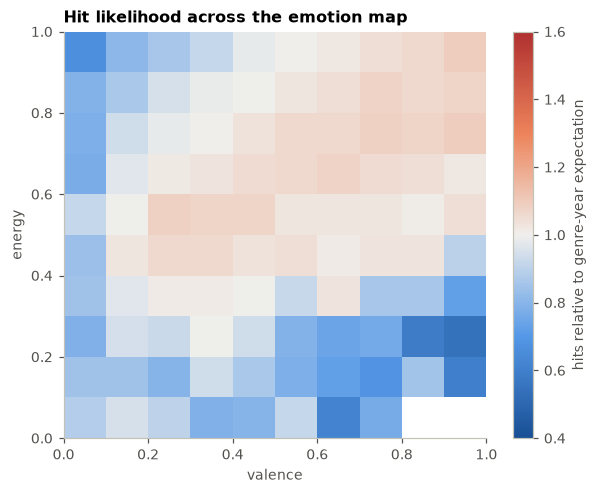

In [20]:
show_figure("12_sadness_surface")

**Interpretation.** Yes, they do. 32,456 low-valence tracks are hits. Their hit rate is 7.9%, against 10.5% for high-valence tracks, and the gap narrows to 6% below expectation within genre and year. The interaction is positive: the valence penalty is smaller for energetic songs (-0.94 percentile points per SD at high energy, -2.27 at low energy).

**Over time.** Yes. The median valence of hits fell by 0.050 per decade from 2000, but the whole sample fell too, and hits stayed slightly brighter than other tracks. Within individual genres the direction is mixed: valence relates negatively to popularity in 34% of genres and positively in 42%.

In [21]:
pd.DataFrame(R["sadness"]["interaction_model"]["coefficients"])

,term,beta,se,ci,p
0,valence,-1.608,0.077,"[-1.7583, -1.4576]",0.000
1,energy,-0.900,0.137,"[-1.1678, -0.63184]",0.000
2,valence_x_energy,0.666,0.073,"[0.52339, 0.80844]",0.000
3,danceability,1.214,0.089,"[1.0405, 1.3881]",0.000
4,acousticness,0.213,0.103,"[0.010481, 0.41481]",0.039
5,loudness,3.042,0.154,"[2.7404, 3.3436]",0.000
6,tempo,0.232,0.036,"[0.16106, 0.3035]",0.000
7,speechiness,-0.338,0.066,"[-0.46833, -0.20824]",0.000
8,instrumentalness,-1.692,0.104,"[-1.8964, -1.487]",0.000
9,liveness,-0.001,0.060,"[-0.11874, 0.11652]",0.985


## 8. Investigation F: geography

#### How do countries' charts differ in sound?

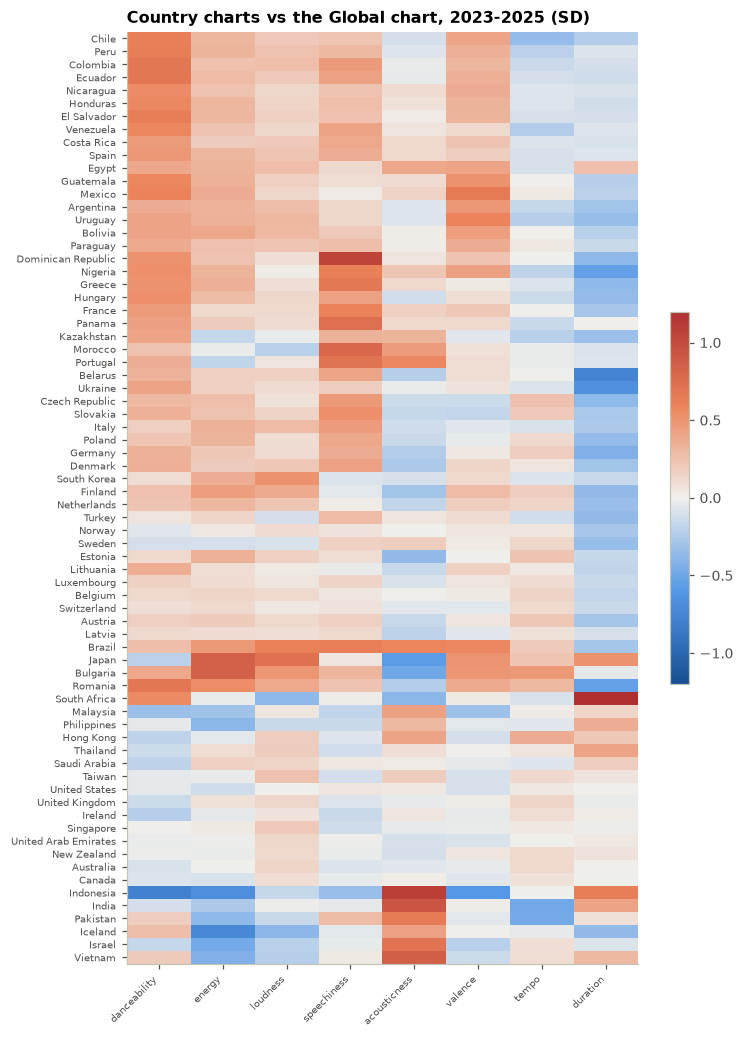

In [22]:
show_figure("13_country_comparison")

**Interpretation.** South Africa, Brazil and Indonesia sit furthest from the Global chart in 2023-2025, while United States, United Arab Emirates and Canada sit closest. Country accounts for at most 15% of chart-weighted variation in any feature (the largest is duration). Those differences are far above chance but small beside the variety within each chart.

#### Are countries' charts converging or diverging?

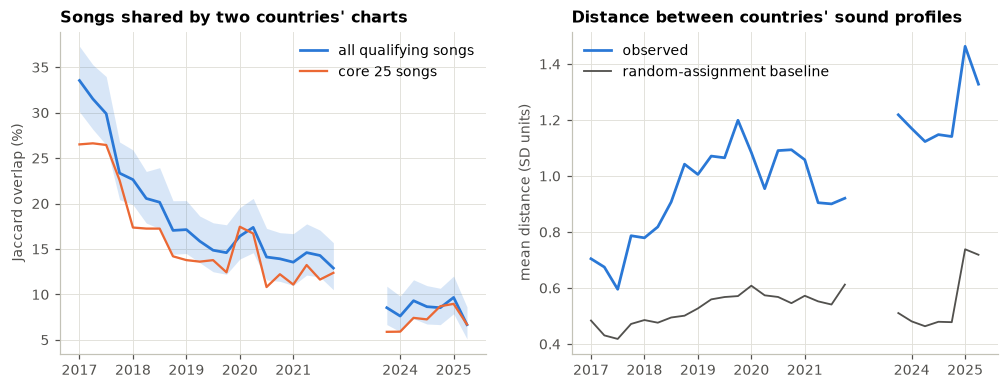

In [23]:
show_figure("14_convergence")

**Interpretation.** Diverging. Two countries' Top 50 lists shared 19% of their songs on average in 2017-2021 and 8% in 2023-2025. The drop remains for a fixed core of 25 songs per country (16% to 7%), and sound profiles moved apart even after allowing for sampling noise. The two periods come from different collections and 2022 is missing, so the size of the step is less certain than its direction.

**Reach.** Most charting songs stay local: 67% reached a Top 50 in just one of the 72 countries, and only 339 of 10,515 reached 20 or more. Songs that travel have lower median valence (0.46 against 0.55), are less danceable and run longer. The differences are small, and language and marketing are not measured here.

**Home artists.** Among chart days whose lead artist could be placed, home-country artists hold the largest share in South Korea (81%), United States (77%) and Colombia (70%). The lookup covers only the most-charted artists, so these are shares of identified chart days, and small local acts are under-counted.

## 9. Investigation G: what makes a hit?

#### Do some kinds of songs last longer on the chart?

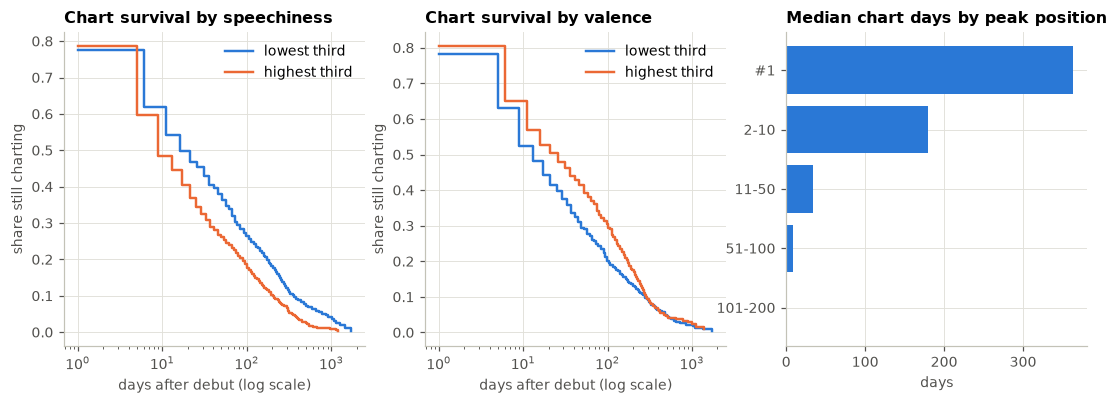

In [24]:
show_figure("15_chart_longevity")

**Interpretation.** Songs in the most speech-heavy third last a median of 8 days on the Global chart, against 16 for the least speech-heavy third. The brightest third lasts 22 days against 12 for the darkest. Peak position separates songs far more: the median #1 song stayed 363 days, while the median song peaking at 101-200 stayed 1.

**Features and chart life.** On the Spotify Global chart, one standard deviation more loudness goes with +29% chart days and more danceability with +26%, while energy (-16%) and speechiness (-15%) go the other way. All audio features together still explain just 4.5% of within-year variation in chart days. These are associations among songs that had already reached the chart.

**Spikes and slow burners.** Among songs that reached the Global Top 50, those earning most of their streams in the first two weeks are less bright (δ -0.31), less danceable (-0.30) and quieter (-0.28) than slow burners from the same year. Many spikes are album tracks that chart briefly on release, so release strategy is a likely part of this pattern.

#### Do popular, lasting and loved music share the same traits?

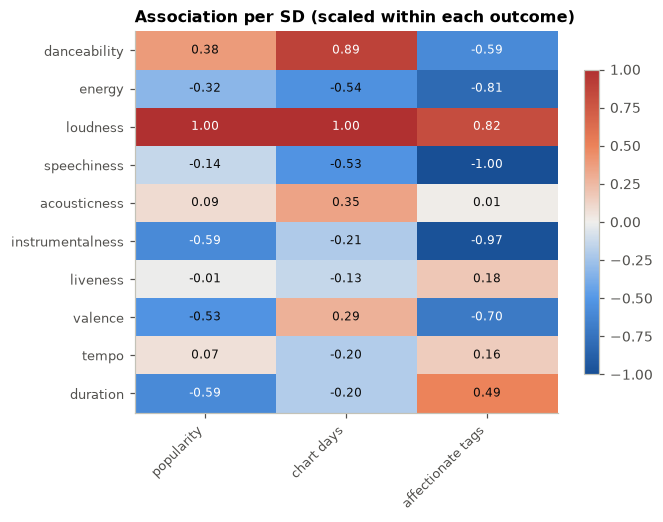

In [25]:
show_figure("16_good_liked_popular")

**Interpretation.** Only partly. Loudness goes with all three outcomes, and speechiness and instrumentalness go against all three. Danceability splits them: it goes with popularity and chart life but slightly against affectionate tags. Longer songs are less popular yet receive more affection. Popularity and affection are only weakly related (Spearman 0.12).

## 10. Hypothesis tests
P-values are adjusted across this table with Benjamini-Hochberg. With samples this large, the effect size matters more than significance.

In [26]:
pd.DataFrame(written["hypotheses"]).drop(columns="significant")

,investigation,claim,method,result,effect,p,q,verdict
0,A,Energy and acousticness move in opposite directions,Spearman correlation,ρ = -0.73,large,<1e-300,<1e-300,Supported
1,A,Mood tags differ in measured energy,Kruskal-Wallis,"H = 15,862",ε² = 0.24,<1e-300,<1e-300,Supported
2,A,Mood tags differ in measured valence,Kruskal-Wallis,"H = 9,363",ε² = 0.14,<1e-300,<1e-300,Supported
3,A,Tagged mood matches the measured mood quadrant,"Chi-square, Cohen's κ","χ² = 18,792","κ = 0.20, V = 0.31",<1e-300,<1e-300,Weak agreement
4,B,Hits are louder than low-popularity tracks,Mann-Whitney,medians -6.4 vs -7.7 dB,δ = 0.21,<1e-300,<1e-300,"Supported, small"
5,B,The loudness gap survives inside genre and year,Mann-Whitney,medians differ by 0.7 dB,δ = 0.10,<1e-300,<1e-300,"Significant, negligible size"
6,B,Hits are less instrumental,Mann-Whitney,hit median near 0,δ = -0.36,<1e-300,<1e-300,"Supported, medium"
7,C,Hot 100 loudness rises over time,"Theil-Sen, Mann-Kendall",+1.01 dB per decade,τ = 0.73,4.0e-17,5.3e-17,Supported
8,C,Hot 100 valence falls over time,"Theil-Sen, Mann-Kendall",-0.033 per decade,τ = -0.75,1.0e-17,1.5e-17,Supported
9,C,Hot 100 tempo trends over time,"Theil-Sen, Mann-Kendall",+0.40 BPM per decade,τ = 0.17,0.054,0.054,Interval includes zero


## 11. Conclusions
- **Popularity: Weakly.** Audio features predict at most 10% of popularity among unseen tracks. The artist's other tracks predict 63%. Sound sets the conditions, and who releases the music explains far more.
- **Emotional perception: Partly.** Measured energy agrees with what listeners tag. Measured valence agrees less, and full mood agreement is weak (κ 0.20).
- **Genre identity: Substantially.** Genre explains up to 51% of the rank variation in a single feature, and audio alone identifies genre about 13 times better than chance.
- **Evolution of the mainstream: Clearly.** Over six decades the Hot 100 became louder, less acoustic and less bright. Song length rose until the 1990s and has fallen since.
- **Geography: Clearly, and it is diverging.** Average chart overlap between countries fell from 19% to 8%. Most charting songs never leave one country.

## 12. Limitations
- Audio features are Spotify's model estimates. Valence in particular is an algorithmic score, and Spotify stopped offering these features to new API users in November 2024.
- Older recordings may be measured from remasters, which can inflate loudness and alter other features for early decades.
- The large Spotify samples were collected through queries and are not random samples of all music. Their genre labels partly reflect that collection.
- Spotify popularity is a current score that favours recent listening, so analyses compare tracks within release year.
- Every chart analysis studies songs that already charted. It cannot show what separates them from songs that never did.
- Audio features could be matched to 83% of 2017-2021 chart streams. 12 countries with weak coverage, often those with strong local repertoire, are left out of that period's sound profiles.
- The two Spotify chart collections differ in source, and no data covers 2022. Changes between them are less certain than changes within either one.
- Marketing budgets, playlist placement, lyrics, language, label support and social media are not measured, so all of these can confound the associations reported here.
- Last.fm tags come from a self-selected community and are concentrated on well-known and Western music.
- No dataset measures whether music is good. Popularity, chart life and affectionate tags are proxies for attention and regard.